<!-- PROFILE LINK -->

 

<h1 style = "text-align:center; font-size: 40px">PROGRAMACIÓN CONCURRENTE Y DISTRIBUIDA</h1>

<a href ="https://github.com/MercedesAC">

<img src="https://avatars.githubusercontent.com/u/77437475?s=400&u=aba620290b95edd285588f755bfe8d848a6feb6b&v=4" style="float:left;vertical-align:centre" width="110" height="110" title = "Mercedes Arauzo Campos 22053428">

<a href ="https://github.com/MercedesAC?tab=repositories">

<img src="https://media-exp1.licdn.com/dms/image/C4D0BAQEu_Aa76fcmPw/company-logo_200_200/0/1630998679429?e=2159024400&v=beta&t=2feC9GG7RWCWizTqsK5HzDWB1TL2DOQuAVwnMf6FFvk" title = "M22" alt="UE" width="110" height="110" style="float:right;vertical-align:centre">

## Driver

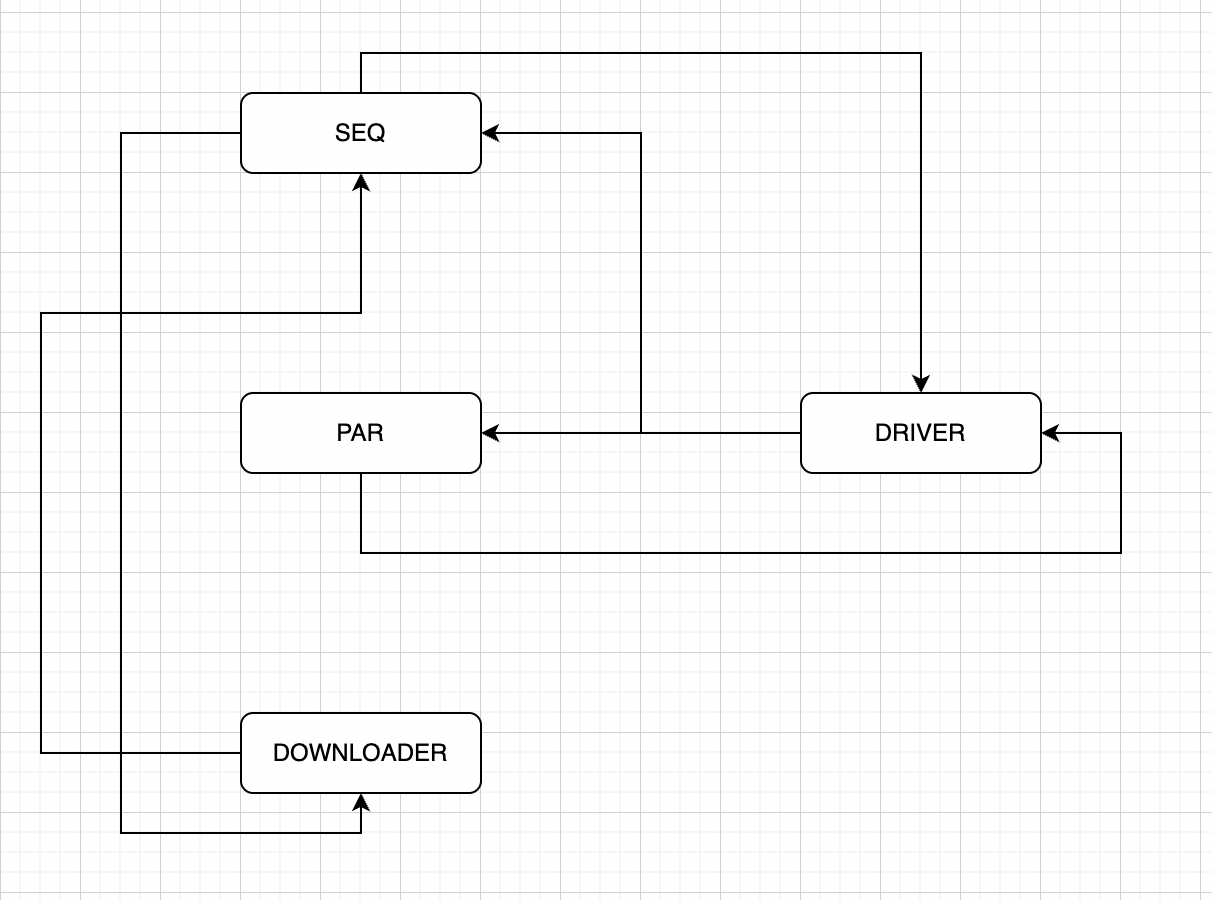

In [5]:
from IPython import display
display.Image("drivers.png", width = 300, height = 300)

In [16]:
import time, urllib.request, multiprocessing as mp, concurrent.futures

In [27]:
def seq_download_images(img_numbers):
    total_bytes=0
    for num in img_numbers:
        total_bytes += _download_image(num)
    return total_bytes

In [28]:
def _download_images(image_numbers):
    print(image_number)
    image_url = 'http://699340.youcanlearnit.net/image{:03d}.jpg'.format(image_numbers)
    try:
        with urllib.request.urlopen(image_url, timeout=60) as conn:
            return len(conn.read())
    except urllib.error.HTTPError:
        print('Oh god, wtf', image_number)
    except Exception as e:
        
        print(e)

In [29]:
def par_download_images(image_numbers):
    total_bytes = 0
    with concurrent.futures.ThreadPoolExecutor() as pool:
        futures = [pool.submit(_download_image, num) for num in image_numbers]
        for f in concurrent.futures.as_completed(futures):
            total_bytes += f.result()
    return total_bytes

In [31]:
if __name__ == '__main__':
    NUM_EVAL_RUNS = 3
    IMAGE_NUMBERS = list(range(1,4))
    sequential_result = seq_download_images(IMAGE_NUMBERS)
    sequential_time = 0
    for i in range(NUM_EVAL_RUNS):
        print(i)
        start = time.perf_counter()
        seq_download_images(IMAGE_NUMBERS)
        sequential_time += time.perf_counter() - start
    sequential_time /= NUM_EVAL_RUNS
    parallel_result = par_download_images(IMAGE_NUMBERS)
    parallel_time = 0
    for i in range(NUM_EVAL_RUNS):
        start = time.perf_counter()
        par_download_images(IMAGE_NUMBERS)
        parallel_time += time.perf_counter() - start
    parallel_time /= NUM_EVAL_RUNS
    
    if sequential_result != parallel_result:
        raise Exception('sequential_result and parallel_result do not match.')
    print ('Average Seequential Time: {:.2f} ms'.format(sequential_time*1000))
    print ('Average Parallel Time: {:.2f} ms'.format(parallel_time*1000))
    print ('Speedup: {:.2f}'.format(sequential_time/parallel_time))
    print ('Efficiency: {:.2f}%'.format(100*(sequential_time/parallel_time)/mp.cpu_count()))

1
2
3
0
1
2
3
1
1
2
3
2
1
2
3
12

3
12

3
12

3
12

3
Average Seequential Time: 2171.89 ms
Average Parallel Time: 915.45 ms
Speedup: 2.37
Efficiency: 29.66%
